# Pandas Examples

---
## Example 1 - Product Demand

In [1]:
import pandas as pd
import numpy as np

In [73]:
# Create a list of products and a list of demands
products = ['Product 1', 'Product 2', 'Product 4', 'Product 6']
demands = [29, 17, 42, 21]

In [74]:
# Create a data set from these two lists
productDataset = list(zip(products, demands))
productDataset

[('Product 1', 29), ('Product 2', 17), ('Product 4', 42), ('Product 6', 21)]

In [75]:
# Create a pandas dataframe
df = pd.DataFrame(data=productDataset, columns=['Product Name', 'Demand'])
df

,Product Name,Demand
0,Product 1,29
1,Product 2,17
2,Product 4,42
3,Product 6,21


#### 1) Print just the column of product names:

#### 2) Print the demand column first, and the product name column second:

#### 3) Print only the first 2 rows of data:

#### 4) Print only the first 2 rows, and only the demand column:

#### 5) Print only the last 2 rows of data.  Print the demand column before the product name column.

#### 6) Sort the products according to decreasing demand:

#### 7)  Find the product with the maximum demand
**NOTE:  Save both the product name and the corresponding maximum demand.  Do not use "for" loops.**

#### 8)  Add a new column of data, named 'Sales Price'

**Assign the values as numpy NaN for now***

#### 9) Assign the following prices to your new column

In [ ]:
prices = [1.99, 2.50, 0.99, 3.75]

#### 10)  Add another column named 'Cost', with the following values

In [ ]:
costs = [1.0, 2.0, 0.5, 2.25]

#### 11) Add yet another column named 'Profit'
**Profit = (sales price) - (cost)**

#### 12)  Add a row of data
**Product 9 has a demand of 99, a sales price of 9.99, a cost of 8.88, and a profit of 1.11**

#### 13) Delete the Sales Price column

#### 14) Make Product Name an index

#### 15)  Filter just for Product 4

#### 16) Filter for products 1 through 4

---

## Example 2 -- Daily Show Guests

In [79]:
# Import the Daily Show guest list
csvFile = 'daily_show_guests.csv'
df = pd.read_csv(csvFile)
df

,YEAR,GoogleKnowlege_Occupation,Show,Group,Raw_Guest_List
0,1999,actor,1/11/99,Acting,Michael J. Fox
1,1999,Comedian,1/12/99,Comedy,Sandra Bernhard
2,1999,television actress,1/13/99,Acting,Tracey Ullman
3,1999,film actress,1/14/99,Acting,Gillian Anderson
4,1999,actor,1/18/99,Acting,David Alan Grier
...,...,...,...,...,...
2688,2015,biographer,7/29/15,Media,Doris Kearns Goodwin
2689,2015,director,7/30/15,Media,J. J. Abrams
2690,2015,stand-up comedian,8/3/15,Comedy,Amy Schumer
2691,2015,actor,8/4/15,Acting,Denis Leary


In [80]:
df.dtypes

YEAR                          int64
GoogleKnowlege_Occupation    object
Show                         object
Group                        object
Raw_Guest_List               object
dtype: object

In [81]:
# Convert the 'Show' date (d/m/YY) to a pandas datestamp
df['date'] = pd.to_datetime(df['Show'], infer_datetime_format=True)
df.head()

,YEAR,GoogleKnowlege_Occupation,Show,Group,Raw_Guest_List,date
0,1999,actor,1/11/99,Acting,Michael J. Fox,1999-01-11
1,1999,Comedian,1/12/99,Comedy,Sandra Bernhard,1999-01-12
2,1999,television actress,1/13/99,Acting,Tracey Ullman,1999-01-13
3,1999,film actress,1/14/99,Acting,Gillian Anderson,1999-01-14
4,1999,actor,1/18/99,Acting,David Alan Grier,1999-01-18


In [82]:
df['Year'] = pd.DatetimeIndex(df['date']).year
df['Month'] = pd.DatetimeIndex(df['date']).month
df['Day'] = pd.DatetimeIndex(df['date']).day
df['Weekday'] = pd.DatetimeIndex(df['date']).weekday
df.head()

,YEAR,GoogleKnowlege_Occupation,Show,Group,Raw_Guest_List,date,Year,Month,Day,Weekday
0,1999,actor,1/11/99,Acting,Michael J. Fox,1999-01-11,1999,1,11,0
1,1999,Comedian,1/12/99,Comedy,Sandra Bernhard,1999-01-12,1999,1,12,1
2,1999,television actress,1/13/99,Acting,Tracey Ullman,1999-01-13,1999,1,13,2
3,1999,film actress,1/14/99,Acting,Gillian Anderson,1999-01-14,1999,1,14,3
4,1999,actor,1/18/99,Acting,David Alan Grier,1999-01-18,1999,1,18,0


In [83]:
# Make the date an index:
df.index = df['date']
df.index.weekday

Int64Index([0, 1, 2, 3, 0, 1, 2, 3, 0, 1,
            ...
            1, 2, 3, 0, 1, 2, 3, 0, 1, 2],
           dtype='int64', name='date', length=2693)

In [84]:
# Weekdays start with 0 (Monday) thru 6 (Sunday)
weekdayList = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

In [85]:
# Get some general information about our dataframe:
df['Group'].describe()

count       2662
unique        17
top       Acting
freq         930
Name: Group, dtype: object

In [11]:
# Create groups:
group = df.groupby('Group').size()
group

Group
Academic          103
Acting            930
Advocacy           24
Athletics          52
Business           25
Clergy              8
Comedy            150
Consultant         18
Government         40
Media             756
Military           16
Misc               45
Musician          123
Political Aide     36
Politician        308
Science            28
dtype: int64

In [21]:
'''
df['Group'][df['Group'] == 'media'] = 'Media'

<ipython-input-10-2504032b7281>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Group'][df['Group'] == 'media'] = 'Media'
'''
df.loc['Group', df['Group'] == 'media'] = 'Media'


KeyError: 'Group'

In [23]:
df['Group'][df['Group'] == 'Media'] = 'media'

<ipython-input-23-1b79fd9f5b04>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Group'][df['Group'] == 'Media'] = 'media'


In [28]:
df.loc[df['Group'] == 'MEDIA', 'Group'] = 'Media'

In [29]:
df['Group'][df['Group'] == 'MEDIA']

Series([], Name: Group, dtype: object)

In [30]:
group = df.groupby('Group').size()
group

Group
Academic          103
Acting            930
Advocacy           24
Athletics          52
Business           25
Clergy              8
Comedy            150
Consultant         18
Government         40
Media             756
Military           16
Misc               45
Musician          123
Political Aide     36
Politician        308
Science            28
dtype: int64

In [31]:
# Create a new DataFrame with just group count info:
counts_df = pd.DataFrame(df.groupby('Group').size().rename('counts'))
counts_df

,counts
Group,
Academic,103
Acting,930
Advocacy,24
Athletics,52
Business,25
Clergy,8
Comedy,150
Consultant,18
Government,40


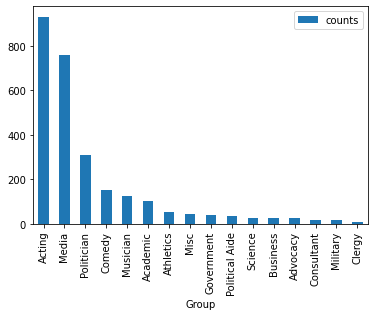

In [32]:
# Create a plot of these counts
import matplotlib.pyplot as plt

Sorted = counts_df.sort_values(['counts'], ascending=False)
Sorted.plot(kind='bar')
plt.show()

In [35]:
# Find records with missing group names
# df[['Group']][pd.isnull(df['Group']) == True]
df[pd.isnull(df['Group'])]

,YEAR,GoogleKnowlege_Occupation,Show,Group,Raw_Guest_List,date,Year,Month,Day,Weekday
date,,,,,,,,,,
1999-12-15,1999,NaN,12/15/99,NaN,Greatest Millennium Special,1999-12-15,1999,12,15,2
1999-07-21,1999,NaN,7/21/99,NaN,Third Anniversary Special,1999-07-21,1999,7,21,2
1999-08-30,1999,NaN,8/30/99,NaN,The Daily Show Summer Spectacular,1999-08-30,1999,8,30,0
2000-11-20,2000,NaN,11/20/00,NaN,Tales of Survival with Vance DeGeneres,2000-11-20,2000,11,20,0
2000-12-13,2000,NaN,12/13/00,NaN,no guest,2000-12-13,2000,12,13,2
2000-07-19,2000,NaN,7/19/00,NaN,Fourth Anniversary Special,2000-07-19,2000,7,19,2
2000-07-31,2000,NaN,7/31/00,NaN,Campaign Trail to the Road to the White House ...,2000-07-31,2000,7,31,0
2001-05-02,2001,NaN,5/2/01,NaN,No guest,2001-05-02,2001,5,2,2
2002-10-14,2002,NaN,10/14/02,NaN,Road to Washington Special,2002-10-14,2002,10,14,0


In [36]:
df.groupby('GoogleKnowlege_Occupation').size()

GoogleKnowlege_Occupation
-                                       1
0                                       4
ADMIRAL                                 2
AUTHOR                                  2
Academic                                3
                                       ..
us senator                             50
vice president                          2
white house official                    1
white house sommunications director     5
writer                                 30
Length: 398, dtype: int64

In [37]:
# Let's find the total number of guests:
df['Raw_Guest_List'].describe()

count               2693
unique              1669
top       Fareed Zakaria
freq                  19
Name: Raw_Guest_List, dtype: object

In [39]:
# Filter for musicians.  Show the musician names:
df[['Raw_Guest_List', 'Group']][df['Group'] == 'Musician']

,Raw_Guest_List,Group
date,,
1999-01-20,Michael Stipe,Musician
1999-10-28,Melanie C,Musician
1999-11-16,Tori Amos,Musician
1999-11-29,Goo Goo Dolls,Musician
1999-11-03,Dave Grohl,Musician
...,...,...
2015-03-11,Common,Musician
2015-04-13,Adam Horovitz,Musician
2015-05-11,John Legend,Musician


In [40]:
# Find how many unique musicians:
df[['Raw_Guest_List']][df['Group'] == 'Musician'].describe()

,Raw_Guest_List
count,123
unique,101
top,Tenacious D
freq,3


In [41]:
# List the unique musicians:
uniqueMusicians = df['Raw_Guest_List'][df['Group'] == 'Musician'].unique()
uniqueMusicians

array(['Michael Stipe', 'Melanie C', 'Tori Amos', 'Goo Goo Dolls',
       'Dave Grohl', 'Jewel', 'John Tesh', 'Sammy Hagar',
       'Hootie & the Blowfish, Billy Crystal', 'Chris Isaak',
       'Chris Robinson', 'Harry Connick Jr.', 'Donny Osmond',
       'Vince Neil', 'LL Cool J', 'Dwight Yoakam',
       'Donny Osmond Marie Osmond', 'Ice Cube', 'Robbie Williams',
       'Alice Cooper', 'Posh Spice & Baby Spice', 'Moby', 'John Lydon',
       'Roger Daltrey', 'Richie Sambora', 'Slash', 'Barenaked Ladies',
       'Spinal Tap', 'Vitamin C', 'Lance Bass', 'Gene Simmons', 'Mí_a',
       'Spice Girls', 'They Might Be Giants', 'Dave Navarro',
       'Tenacious D', 'Ja Rule', 'Christina Aguilera', 'Jakob Dylan',
       'Barry Manilow', 'The Goo Goo Dolls', 'Elvis Costello',
       'Alanis Morissette', 'Busta Rhymes', 'Wyclef Jean', 'Ringo Starr',
       'Randy Jackson', 'Ludacris', 'Kelly Clarkson', 'Tyrese Gibson',
       'John Popper', 'Norah Jones', 'Wynton Marsalis',
       'Melissa Etheri

In [45]:
# How many total times did a musician appear?
df['Raw_Guest_List'][df['Group'] == 'Musician'].count()

123

In [59]:
# How many times did each musician appear?
df2 = pd.DataFrame(df['Raw_Guest_List'][df['Group'] == 'Musician'])
df2

,Raw_Guest_List
date,
1999-01-20,Michael Stipe
1999-10-28,Melanie C
1999-11-16,Tori Amos
1999-11-29,Goo Goo Dolls
1999-11-03,Dave Grohl
...,...
2015-03-11,Common
2015-04-13,Adam Horovitz
2015-05-11,John Legend


In [63]:
# How many times did each musician appear?
df2 = pd.DataFrame(df['Raw_Guest_List'][df['Group'] == 'Musician'])
df3 = pd.DataFrame(df2.groupby('Raw_Guest_List').size())
df3

,0
Raw_Guest_List,
Adam Horovitz,1
Adam Levine,1
Al Green,1
Alanis Morissette,1
Alice Cooper,1
...,...
Vitamin C,1
Willie Nelson,2
Wu-Tang Clan,1


In [65]:
# List all musicians, sort by number of appearances in descending order
df3.sort_values([0], ascending=False)

,0
Raw_Guest_List,
Tenacious D,3
Dave Grohl,3
Randy Jackson,3
Wynton Marsalis,2
Ringo Starr,2
...,...
Gene Simmons,1
Foo Fighters,1
Esperanza Spalding,1


In [60]:
df2.groupby('Raw_Guest_List').size()

Raw_Guest_List
Adam Horovitz        1
Adam Levine          1
Al Green             1
Alanis Morissette    1
Alice Cooper         1
                    ..
Vitamin C            1
Willie Nelson        2
Wu-Tang Clan         1
Wyclef Jean          1
Wynton Marsalis      2
Length: 101, dtype: int64

In [66]:
# Find the guests that appeared in 2010
# Option 1 (use the year column):
df[['Raw_Guest_List']][df['Year'] == 2010]

,Raw_Guest_List
date,
2010-01-11,John Yoo
2010-01-12,Paul Ingrassia
2010-01-13,Ringo Starr and The Ben Harper Band
2010-01-13,Ringo Starr and The Ben Harper Band
2010-01-14,Tom Brokaw
...,...
2010-09-29,Linda Polman
2010-09-30,Justin Timberlake
2010-09-07,Tim Gunn


In [72]:
# Option 2 (use the date index):
# print(df[['Raw_Guest_List', 'Group']].loc['2010-1-1':'2010-12-31'])
df[['Raw_Guest_List', 'Group']].loc['2010-09-01':'2010-09-30']

,Raw_Guest_List,Group
date,,
2010-09-13,Ben Affleck,Acting
2010-09-14,Tony Blair,Politician
2010-09-15,Jon Hamm,Acting
2010-09-16,President Bill Clinton,Politician
2010-09-20,President Jimmy Carter,Politician
2010-09-21,Sigourney Weaver,Acting
2010-09-22,Edward Norton,Acting
2010-09-23,H.M. Abdullah II,Politician
2010-09-27,Bill O'Reilly,Media


In [86]:
# Find the guests that appeared in 2010 and were actors
df[['Raw_Guest_List', 'Group']][df['Group'] == 'Acting'].loc['2010-1-1':'2010-12-31']

,Raw_Guest_List,Group
date,,
2010-01-19,Colin Firth,Acting
2010-01-21,Julie Andrews,Acting
2010-01-07,Maggie Gyllenhaal,Acting
2010-10-11,Johnny Knoxville,Acting
2010-10-05,Bruce Willis,Acting
2010-10-07,Naomi Watts,Acting
2010-11-11,Rosario Dawson,Acting
2010-11-29,Judah Friedlander,Acting
2010-11-09,Harrison Ford,Acting


In [87]:
df[['Raw_Guest_List', 'Group']][df['Group'] == 'Acting'].loc['2010-1-1':'2010-12-31'].describe()

,Raw_Guest_List,Group
count,45,45
unique,44,1
top,Tracy Morgan,Acting
freq,2,45


In [88]:
# Find the guests that appeared in November and were politicians
df[['Raw_Guest_List']][(df['Month'] == 11) & (df['Group'] == 'Politician')]

,Raw_Guest_List
date,
2000-11-06,Arlen Specter
2000-11-07,Bob Dole
2002-11-19,Harold Ford
2002-11-05,John McCain
2004-11-15,Kay Bailey Hutchison
2004-11-02,William Weld & Al Sharpton
2004-11-03,Sen. Charles Schumer
2005-11-01,Sen. Barbara Boxer
2005-11-30,Rep. Nancy Pelosi


In [103]:
# Count the number of shows by weekday
weekday_counts = df.groupby('Weekday').count()
weekday_counts[['Year']]

,Year
Weekday,
0,623
1,689
2,693
3,678
4,9
6,1



---

## Example 3 -- Scraping HTML Tables

*This material comes from Wes McKinney's textbook*

In [4]:
tables = pd.read_html('https://www.fdic.gov/resources/resolutions/bank-failures/failed-bank-list/')

In [5]:
tables

[                         Bank NameBank           CityCity StateSt  CertCert  \
 0                       Signature Bank           New York      NY     57053   
 1                  Silicon Valley Bank        Santa Clara      CA     24735   
 2                    Almena State Bank             Almena      KS     15426   
 3           First City Bank of Florida  Fort Walton Beach      FL     16748   
 4                 The First State Bank      Barboursville      WV     14361   
 ..                                 ...                ...     ...       ...   
 560                 Superior Bank, FSB           Hinsdale      IL     32646   
 561                Malta National Bank              Malta      OH      6629   
 562    First Alliance Bank & Trust Co.         Manchester      NH     34264   
 563  National State Bank of Metropolis         Metropolis      IL      3815   
 564                   Bank of Honolulu           Honolulu      HI     21029   
 
                  Acquiring Institutio

In [96]:
# How many tables did we find on this webpage?
len(tables)

NameError: name 'tables' is not defined

In [105]:
pd.read_html?

In [97]:
# Our "failure" data will be in the first (and only) table:
failures = tables[0]

NameError: name 'tables' is not defined

In [98]:
failures.head()

NameError: name 'failures' is not defined

In [99]:
# How many bank failures were there per year?
close_timestamps = pd.to_datetime(failures['Closing Date'])
close_timestamps.dt.year.value_counts()

NameError: name 'failures' is not defined

In [ ]:
# Which bank failures were in NY?
failures[failures['ST'] == 'NY']

In [ ]:
# How many bank failures were in NY?
failures[failures['ST'] == 'NY']['ST'].count()


---

## Further Studying

Check out https://realpython.com/python-data-cleaning-numpy-pandas/ for some more examples.